In [ ]:
from pathlib import Path
import os

# notebooks live in ai/notebooks/; data paths are relative to ai/
os.chdir(Path("..").resolve())


# noise and gamma

Two fake versions of every real image:

- gaussian noise, sigma 20
- gamma change, either 0.55 (brighter) or 1.8 (darker)

Seed is 42 and the csv is read in its saved order, so running this again makes the same files. The fake stays in the same split as the real image. Nothing is trained here.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

split_df = pd.read_csv("metadata/split.csv")
SEED = 42
SIGMA = 20
out_root = Path("fake")
len(split_df)

7200

In [2]:
def add_noise(img, rng):
    arr = np.asarray(img).astype(np.float32)
    noisy = arr + rng.normal(0, SIGMA, arr.shape)
    return Image.fromarray(np.clip(noisy, 0, 255).astype(np.uint8))


def shift_gamma(img, gamma):
    arr = np.asarray(img).astype(np.float32) / 255.0
    out = np.clip(arr ** gamma, 0, 1)
    return Image.fromarray((out * 255).astype(np.uint8))


def save_jpg(img, path):
    for _ in range(5):
        try:
            img.save(path, quality=95)
            return
        except PermissionError:
            time.sleep(0.3)
    img.save(path, quality=95)


rng = np.random.default_rng(SEED)
records = []

for i, row in split_df.iterrows():
    src = Path(row.path)
    rel = src.relative_to("data")
    noise_path = out_root / "gaussian_noise" / rel
    gamma_path = out_root / "gamma" / rel
    noise_path.parent.mkdir(parents=True, exist_ok=True)
    gamma_path.parent.mkdir(parents=True, exist_ok=True)

    if noise_path.exists() and gamma_path.exists():
        gamma = float(rng.choice([0.55, 1.8]))
        with Image.open(noise_path) as done:
            shape = np.asarray(done).shape
        rng.normal(0, SIGMA, shape)
    else:
        img = Image.open(src).convert("RGB")
        gamma = float(rng.choice([0.55, 1.8]))
        save_jpg(add_noise(img, rng), noise_path)
        save_jpg(shift_gamma(img, gamma), gamma_path)

    records.append({
        "real_path": row.path,
        "fake_path": noise_path.as_posix(),
        "attack": "gaussian_noise",
        "param": SIGMA,
        "folder": row.folder,
        "split": row.split,
        "seed": SEED,
    })
    records.append({
        "real_path": row.path,
        "fake_path": gamma_path.as_posix(),
        "attack": "gamma",
        "param": gamma,
        "folder": row.folder,
        "split": row.split,
        "seed": SEED,
    })

    if (i + 1) % 1000 == 0:
        print(i + 1, "images")

log = pd.DataFrame(records)
log.to_csv("metadata/attacks_noise_gamma.csv", index=False)
print("saved", len(log), "fake rows")
log.attack.value_counts()

1000 images


2000 images


3000 images


4000 images


5000 images


6000 images


7000 images


saved 14400 fake rows


attack
gaussian_noise    7200
gamma             7200
Name: count, dtype: int64

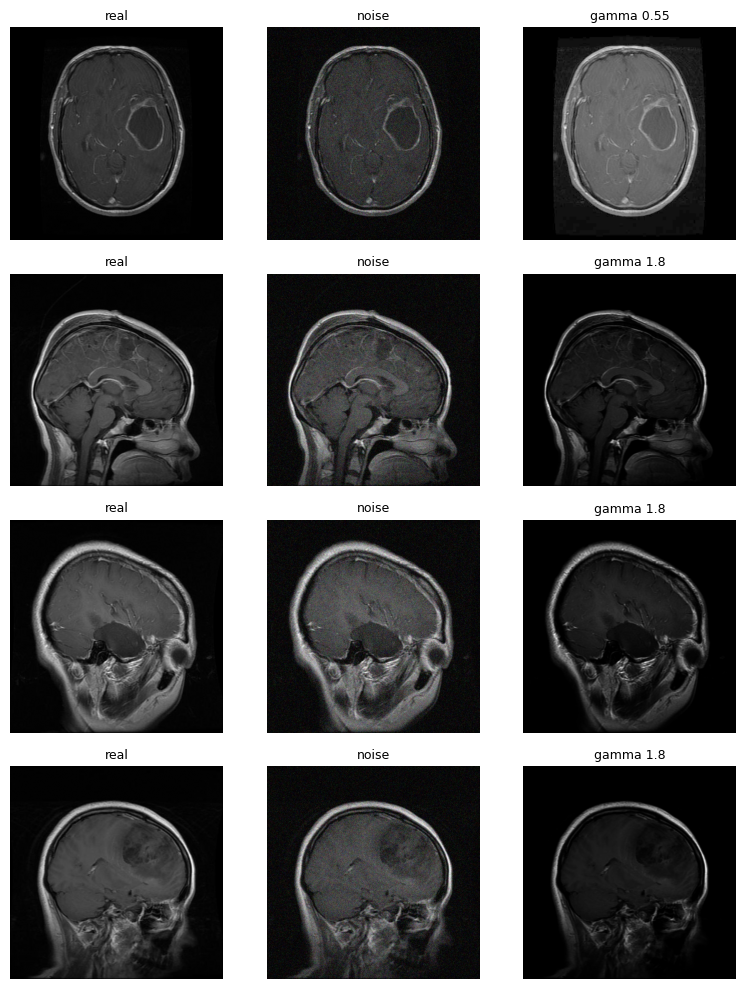

In [3]:
# a few real / noise / gamma triples, just to see the attack
show = log.drop_duplicates("real_path").head(4)
fig, axes = plt.subplots(4, 3, figsize=(8, 10))

for r, real_path in enumerate(show.real_path):
    noise_path = log[(log.real_path == real_path) & (log.attack == "gaussian_noise")].fake_path.iloc[0]
    gamma_path = log[(log.real_path == real_path) & (log.attack == "gamma")].fake_path.iloc[0]
    gamma_value = log[(log.real_path == real_path) & (log.attack == "gamma")].param.iloc[0]
    titles = ["real", "noise", "gamma " + str(gamma_value)]
    for c, path in enumerate([real_path, noise_path, gamma_path]):
        axes[r, c].imshow(Image.open(path), cmap="gray")
        axes[r, c].set_title(titles[c], fontsize=9)
        axes[r, c].axis("off")

plt.tight_layout()
plt.show()